In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import pandas as pd
import numpy as np
%matplotlib inline


In [16]:
X,y = make_blobs(n_samples=1000, centers=3, n_features=2)

In [17]:
X

array([[  1.20893628, -10.72402224],
       [ -2.22923038, -10.4372907 ],
       [ -3.56842306, -10.04464348],
       ...,
       [ -3.81825128,  -9.29361421],
       [ -1.52878746, -10.61985344],
       [ -3.23610547, -10.57920586]], shape=(1000, 2))

In [18]:
y

array([1, 2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 0, 1, 0, 0, 2, 0, 1, 1, 2, 2, 0,
       2, 1, 1, 1, 0, 2, 2, 1, 2, 0, 1, 1, 0, 2, 2, 1, 0, 1, 2, 1, 1, 2,
       0, 2, 2, 1, 0, 0, 0, 1, 2, 1, 0, 2, 1, 2, 0, 2, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 2, 0, 1, 0, 0, 2, 1, 2, 1, 0, 1, 0, 0, 2, 2, 1, 0, 2, 0,
       1, 1, 0, 1, 0, 2, 1, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 1,
       0, 2, 1, 0, 0, 0, 1, 2, 0, 2, 2, 1, 2, 0, 2, 0, 0, 0, 2, 1, 2, 1,
       0, 0, 0, 1, 1, 0, 1, 1, 2, 2, 2, 0, 2, 0, 1, 0, 2, 2, 1, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 2, 2, 2, 0, 2, 2, 1, 0,
       1, 2, 1, 2, 0, 2, 0, 2, 0, 0, 2, 0, 0, 0, 0, 2, 1, 2, 1, 1, 0, 2,
       1, 1, 1, 2, 2, 0, 2, 1, 2, 0, 1, 0, 2, 0, 0, 1, 0, 1, 2, 1, 1, 0,
       2, 0, 2, 2, 1, 0, 2, 2, 0, 2, 2, 0, 1, 2, 2, 0, 2, 2, 0, 2, 0, 0,
       2, 0, 1, 1, 2, 2, 0, 0, 2, 2, 1, 2, 1, 2, 0, 2, 2, 2, 1, 0, 1, 1,
       2, 1, 2, 0, 0, 0, 0, 2, 2, 1, 1, 2, 1, 0, 1, 0, 2, 0, 1, 2, 1, 0,
       2, 2, 2, 1, 1, 2, 1, 0, 2, 0, 2, 1, 2, 0, 0,

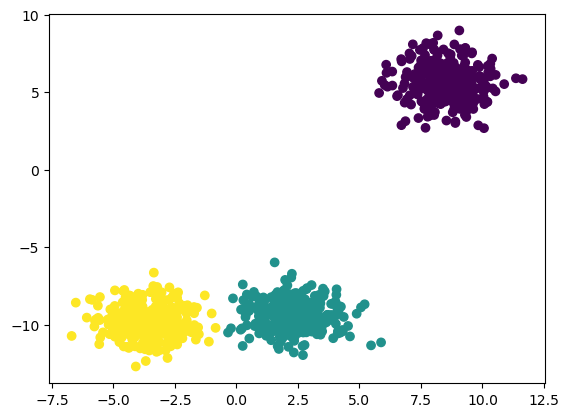

In [19]:
plt.scatter(X[:,0],X[:,1],c=y)

In [20]:
# Standardization

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.33,random_state=42)

In [22]:
X_train_scaled = scaler.fit_transform(X_train)

In [23]:
X_test_scaled = scaler.transform(X_test)

In [24]:
from sklearn.cluster import KMeans

In [26]:
# Elbow Method
wcss = []
for k in range(1,11):
    kmeans =KMeans(n_clusters=k, init='k-means++')
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)


c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

In [27]:
wcss

[1340.0000000000002,
 194.58640208326653,
 36.87930707110721,
 31.69753955039533,
 26.84466273160964,
 21.79559901244676,
 20.27952454604637,
 18.27858441842932,
 16.769969775969088,
 15.320884877086407]

Text(0, 0.5, 'WCSS')

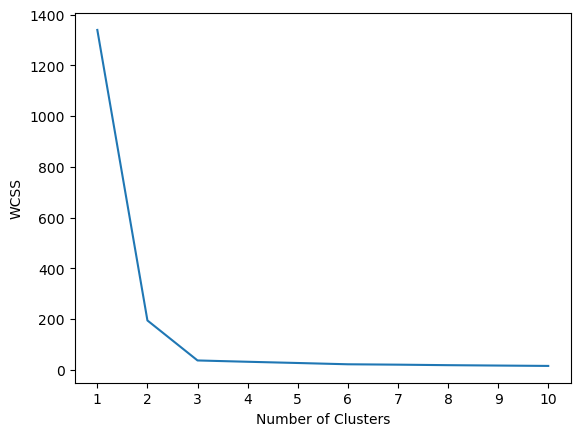

In [28]:
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

In [29]:
kmeans = KMeans(n_clusters=3, init='k-means++')

In [30]:
kmeans.fit_predict(X_train_scaled)

c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


array([2, 2, 1, 2, 2, 2, 2, 1, 0, 2, 0, 1, 0, 1, 2, 0, 1, 0, 1, 1, 0, 2,
       2, 0, 0, 2, 1, 1, 2, 0, 1, 1, 2, 2, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 2, 1, 2, 1, 1, 1, 1, 0, 0, 2, 0, 1, 1, 2, 1, 2, 2, 0, 1, 2,
       2, 2, 1, 0, 2, 1, 1, 0, 0, 0, 1, 0, 2, 1, 2, 2, 2, 0, 1, 1, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 0, 1, 2, 0, 1, 1, 2, 1, 2, 2, 1, 0, 0, 0,
       0, 0, 0, 1, 2, 0, 2, 2, 2, 2, 1, 1, 2, 2, 1, 0, 1, 1, 1, 2, 0, 1,
       2, 1, 0, 1, 1, 2, 0, 0, 1, 1, 0, 2, 1, 2, 2, 2, 0, 2, 1, 2, 1, 2,
       0, 0, 2, 1, 2, 1, 0, 0, 1, 1, 1, 2, 1, 2, 0, 0, 1, 0, 1, 1, 1, 2,
       1, 1, 2, 2, 0, 0, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 2, 1, 1, 1, 2, 1,
       1, 0, 0, 1, 1, 2, 1, 0, 2, 2, 2, 1, 1, 0, 0, 1, 0, 2, 0, 2, 0, 1,
       2, 1, 2, 0, 1, 2, 2, 1, 0, 0, 2, 0, 1, 2, 2, 0, 1, 1, 2, 1, 0, 0,
       1, 1, 2, 2, 0, 2, 0, 2, 2, 0, 2, 2, 1, 0, 1, 0, 1, 1, 2, 0, 1, 0,
       0, 2, 0, 2, 0, 1, 2, 1, 0, 0, 2, 1, 1, 1, 2, 2, 1, 2, 0, 1, 0, 2,
       2, 2, 2, 0, 1, 2, 1, 1, 1, 1, 1, 2, 2, 0, 1,

In [31]:
y_pred = kmeans.predict(X_test_scaled)

In [32]:
y_pred

array([0, 2, 2, 2, 1, 1, 1, 1, 0, 2, 0, 0, 0, 0, 1, 2, 0, 1, 1, 1, 0, 2,
       1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 2, 2, 1, 2, 0, 0, 0, 0, 1, 1, 2, 1,
       1, 1, 2, 2, 0, 1, 0, 1, 1, 1, 2, 0, 1, 0, 1, 0, 0, 1, 2, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 2, 1, 2, 2, 1, 2, 1, 2, 0, 2, 0, 2, 1, 0, 0, 1,
       1, 1, 2, 0, 0, 2, 0, 2, 0, 2, 1, 2, 1, 0, 1, 1, 1, 1, 2, 2, 0, 0,
       0, 0, 2, 1, 0, 1, 1, 2, 2, 0, 1, 1, 1, 2, 0, 2, 2, 0, 0, 2, 2, 0,
       2, 0, 0, 0, 0, 2, 2, 1, 1, 0, 1, 1, 2, 1, 2, 2, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 0, 2, 1, 2, 0, 0, 2, 2, 1, 2, 1, 1, 1, 0, 0,
       2, 0, 1, 2, 2, 2, 2, 2, 2, 1, 2, 0, 0, 2, 0, 1, 0, 2, 2, 1, 1, 2,
       2, 1, 2, 2, 0, 1, 2, 0, 2, 1, 2, 1, 2, 0, 2, 2, 1, 0, 1, 1, 2, 2,
       1, 2, 1, 1, 0, 0, 1, 1, 2, 1, 1, 1, 1, 0, 2, 1, 1, 2, 2, 2, 0, 0,
       0, 1, 0, 2, 1, 2, 2, 0, 0, 0, 0, 2, 2, 1, 1, 2, 0, 0, 2, 2, 0, 0,
       2, 0, 0, 0, 2, 1, 0, 1, 1, 0, 1, 1, 1, 2, 1, 0, 1, 2, 0, 2, 1, 2,
       0, 1, 0, 0, 2, 0, 2, 0, 2, 1, 1, 2, 1, 2, 1,

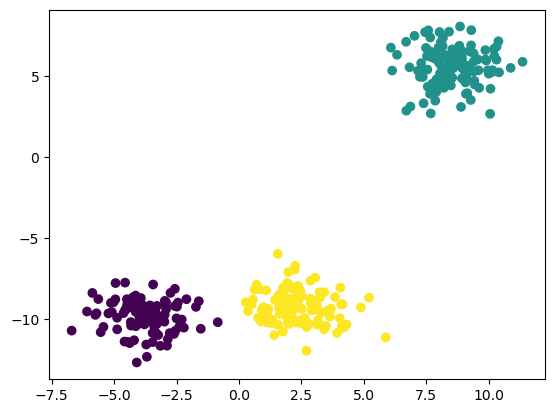

In [34]:
plt.scatter(X_test[:,0],X_test[:,1],c=y_pred)

In [35]:
## Validating the k value
## Kneelocator
#silhoutee scoring  

In [36]:
# kneelocator
!pip install kneed


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iamsi\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [37]:
from kneed import KneeLocator

In [38]:
kl = KneeLocator(range(1,11),wcss,curve='convex',direction='decreasing')

In [39]:
kl.elbow

np.int64(3)

In [40]:
## Silhouette scoring
from sklearn.metrics import silhouette_score

In [41]:
silhouette_coeff = []
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, init='k-means++')
    kmeans.fit(X_train_scaled)
    score = silhouette_score(X_train_scaled,kmeans.labels_)
    silhouette_coeff.append(score)

c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\iamsi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

In [42]:
silhouette_coeff

[0.7850329910318798,
 0.7908644236396494,
 0.6461393149384668,
 0.477213009373597,
 0.4719990011191451,
 0.3373925629106348,
 0.3195086309935803,
 0.3304699685394144,
 0.3203314581226357]

Text(0, 0.5, 'Silhouette Coefficient')

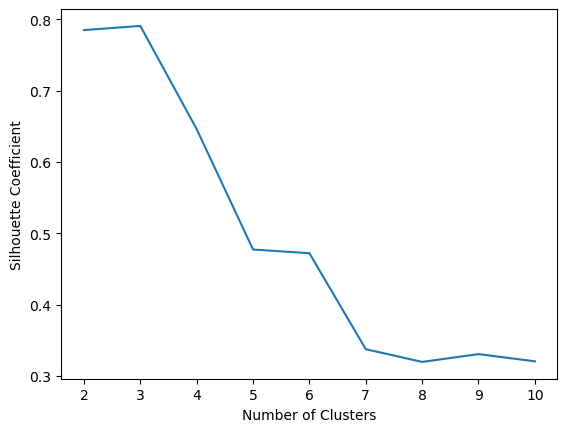

In [43]:
plt.plot(range(2,11),silhouette_coeff)
plt.xticks(range(2,11))
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Coefficient')